In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
!pip install -q torch-fidelity

In [3]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.utils import make_grid, save_image
import json
import torch_fidelity
from torch.utils.data import Dataset
import pandas as pd


In [4]:
torch.manual_seed(42) # sets the random seed for PyTorch, helping to reproduce random results. Since in DDPM, randomness affects initial model weights, added noise, and sampled timesteps

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


# Sinusoidal timestep embedding

In [5]:
# Converts each timestep into a vector. The U-Net then processes this vector and passes it into every residual block
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()

        if embedding_dim < 4 or embedding_dim % 2 != 0:
            raise ValueError(
                "embedding_dim must be even and at least 4."
            )

        half_dim = embedding_dim // 2

        frequencies = torch.exp(
            -math.log(10000)
            * torch.arange(half_dim, dtype=torch.float32)
            / (half_dim - 1)
        )

        self.register_buffer("frequencies", frequencies)

    def forward(self, timesteps):
        # timesteps: [batch]
        angles = (
            timesteps.float().unsqueeze(1)
            * self.frequencies.unsqueeze(0)
        )

        # Output: [batch, embedding_dim]
        return torch.cat(
            [angles.sin(), angles.cos()],
            dim=1
        )

# Residual block with time conditioning

In [6]:
# timestep vector is projected to match the feature channels and added to the intermediate image features.
class TimeResidualBlock(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        time_dim,
        dropout=0.1
    ):
        super().__init__()

        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.time_projection = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_dim, out_channels)
        )

        self.norm2 = nn.GroupNorm(8, out_channels)
        self.dropout = nn.Dropout(dropout)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.shortcut = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )
        )

    def forward(self, x, time_embedding):
        h = self.conv1(F.silu(self.norm1(x)))

        time_features = self.time_projection(
            time_embedding
        )

        # [batch, channels] -> [batch, channels, 1, 1]
        h = h + time_features[:, :, None, None]

        h = self.norm2(h)
        h = F.silu(h)
        h = self.dropout(h)
        h = self.conv2(h)

        return h + self.shortcut(x)

# Spatial self-attention

In [7]:
# lets features at different image positions interact. The U-Net uses it at 16 × 16 and 8 × 8.
class SpatialAttention(nn.Module):
    def __init__(self, channels, num_heads=4):
        super().__init__()

        self.norm = nn.GroupNorm(8, channels)

        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=num_heads,
            batch_first=True
        )

    def forward(self, x):
        batch, channels, height, width = x.shape

        h = self.norm(x)

        # [B, C, H, W] -> [B, H*W, C]
        h = h.flatten(2).transpose(1, 2)

        h, _ = self.attention(
            h,
            h,
            h,
            need_weights=False
        )

        # [B, H*W, C] -> [B, C, H, W]
        h = h.transpose(1, 2).reshape(
            batch, channels, height, width
        )

        return x + h

# Full U-Net

In [8]:
# The encoder reduces resolution from 32 → 16 → 8. The decoder restores it to 32 × 32, using encoder features through skip connections.
class DiffusionUNet(nn.Module):
    def __init__(
        self,
        image_channels=3,
        base_channels=64,
        time_dim=256,
        dropout=0.1
    ):
        super().__init__()

        if base_channels % 8 != 0:
            raise ValueError(
                "base_channels must be divisible by 8."
            )

        c = base_channels

        # Timestep embedding
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(c),
            nn.Linear(c, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        # Input: 32 x 32
        self.input_conv = nn.Conv2d(
            image_channels, c, kernel_size=3, padding=1
        )

        # Encoder: 32 x 32
        self.encoder1 = TimeResidualBlock(
            c, c, time_dim, dropout
        )

        # 32 -> 16
        self.downsample1 = nn.Conv2d(
            c, 2 * c,
            kernel_size=4, stride=2, padding=1
        )

        # Encoder: 16 x 16
        self.encoder2 = TimeResidualBlock(
            2 * c, 2 * c, time_dim, dropout
        )
        self.encoder_attention = SpatialAttention(2 * c)

        # 16 -> 8
        self.downsample2 = nn.Conv2d(
            2 * c, 4 * c,
            kernel_size=4, stride=2, padding=1
        )

        # Bottleneck: 8 x 8
        self.middle1 = TimeResidualBlock(
            4 * c, 4 * c, time_dim, dropout
        )
        self.middle_attention = SpatialAttention(4 * c)
        self.middle2 = TimeResidualBlock(
            4 * c, 4 * c, time_dim, dropout
        )

        # 8 -> 16
        self.upsample1 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(
                4 * c, 2 * c, kernel_size=3, padding=1
            )
        )

        # Concatenate 2c decoder + 2c encoder channels
        self.decoder2 = TimeResidualBlock(
            4 * c, 2 * c, time_dim, dropout
        )
        self.decoder_attention = SpatialAttention(2 * c)

        # 16 -> 32
        self.upsample2 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(
                2 * c, c, kernel_size=3, padding=1
            )
        )

        # Concatenate c decoder + c encoder channels
        self.decoder1 = TimeResidualBlock(
            2 * c, c, time_dim, dropout
        )

        self.output_norm = nn.GroupNorm(8, c)

        self.output_conv = nn.Conv2d(
            c,
            image_channels,
            kernel_size=3,
            padding=1
        )

    def forward(self, x, timesteps):
        time_embedding = self.time_mlp(timesteps)

        x = self.input_conv(x)

        # Save encoder features for skip connections
        skip1 = self.encoder1(x, time_embedding)

        x = self.downsample1(skip1)

        skip2 = self.encoder2(x, time_embedding)
        skip2 = self.encoder_attention(skip2)

        x = self.downsample2(skip2)

        x = self.middle1(x, time_embedding)
        x = self.middle_attention(x)
        x = self.middle2(x, time_embedding)

        x = self.upsample1(x)
        x = torch.cat([x, skip2], dim=1)
        x = self.decoder2(x, time_embedding)
        x = self.decoder_attention(x)

        x = self.upsample2(x)
        x = torch.cat([x, skip1], dim=1)
        x = self.decoder1(x, time_embedding)

        x = F.silu(self.output_norm(x))

        # Predict unrestricted Gaussian noise:
        # no sigmoid or tanh on the output
        return self.output_conv(x)

# Create the model and check its output

In [9]:
model = DiffusionUNet(
    image_channels=3,
    base_channels=64,
    time_dim=256,
    dropout=0.1
).to(device)

parameter_count = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {parameter_count:,}")

model.eval()

with torch.no_grad():
    dummy_images = torch.randn(
        2, 3, 32, 32, device=device
    )

    dummy_timesteps = torch.tensor(
        [0, 999],
        device=device,
        dtype=torch.long
    )

    predicted_noise = model(
        dummy_images,
        dummy_timesteps
    )

assert predicted_noise.shape == dummy_images.shape
assert torch.isfinite(predicted_noise).all()

print("Input shape:", dummy_images.shape)
print("Output shape:", predicted_noise.shape)

model.train()

Trainable parameters: 5,065,027
Input shape: torch.Size([2, 3, 32, 32])
Output shape: torch.Size([2, 3, 32, 32])


DiffusionUNet(
  (time_mlp): Sequential(
    (0): SinusoidalTimeEmbedding()
    (1): Linear(in_features=64, out_features=256, bias=True)
    (2): SiLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
  )
  (input_conv): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (encoder1): TimeResidualBlock(
    (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (time_projection): Sequential(
      (0): SiLU()
      (1): Linear(in_features=256, out_features=64, bias=True)
    )
    (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (shortcut): Identity()
  )
  (downsample1): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (encoder2): TimeResidualBlock(
    (norm1): GroupNorm(8, 128, eps=1e-05, affine=True)
    (conv1): Conv2d(128, 128, k

# Choose and prepare the noise schedule

In [10]:
TIMESTEPS = 1000
SCHEDULE = "cosine"  # Use "linear" for a separate experiment


def make_beta_schedule(schedule, timesteps):
    if schedule == "linear":
        return torch.linspace(
            1e-4,
            0.02,
            timesteps,
            dtype=torch.float32
        )

    if schedule == "cosine":
        s = 0.008

        steps = torch.linspace(
            0,
            timesteps,
            timesteps + 1,
            dtype=torch.float64
        )

        curve = torch.cos(
            ((steps / timesteps + s) / (1 + s))
            * math.pi / 2
        ).square()

        curve = curve / curve[0]

        betas = 1.0 - curve[1:] / curve[:-1]

        return betas.clamp(1e-8, 0.999).float()

    raise ValueError("Choose 'linear' or 'cosine'.")


betas = make_beta_schedule(
    SCHEDULE, TIMESTEPS
).to(device)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

alpha_bars_prev = torch.cat([
    torch.ones(1, device=device),
    alpha_bars[:-1]
])

sqrt_alpha_bars = alpha_bars.sqrt()

sqrt_one_minus_alpha_bars = (
    1.0 - alpha_bars
).sqrt()

posterior_variance = (
    betas
    * (1.0 - alpha_bars_prev)
    / (1.0 - alpha_bars)
)

posterior_mean_coef1 = (
    betas
    * alpha_bars_prev.sqrt()
    / (1.0 - alpha_bars)
)

posterior_mean_coef2 = (
    (1.0 - alpha_bars_prev)
    * alphas.sqrt()
    / (1.0 - alpha_bars)
)


def add_noise(clean_images, timesteps):
    noise = torch.randn_like(clean_images)

    signal_scale = sqrt_alpha_bars[
        timesteps
    ].view(-1, 1, 1, 1)

    noise_scale = sqrt_one_minus_alpha_bars[
        timesteps
    ].view(-1, 1, 1, 1)

    noisy_images = (
        signal_scale * clean_images
        + noise_scale * noise
    )

    return noisy_images, noise


print("Schedule:", SCHEDULE)
print("Timesteps:", TIMESTEPS)

Schedule: cosine
Timesteps: 1000


# Restore data and check the training loss

In [12]:
PROJECT_DIR = Path("/content/drive/MyDrive/DDPM")
DATA_DIR = PROJECT_DIR / "data"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Restore the original split from the cosine checkpoint
reference = torch.load(
    PROJECT_DIR / "ddpm_cosine_epoch_200.pt",
    map_location="cpu",
    weights_only=True
)

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

train_source = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=train_transform
)

train_data = Subset(
    train_source,
    reference["train_indices"]
)

train_loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    persistent_workers=True,
    generator=torch.Generator().manual_seed(42)
)

print("Device:", device)
print("Training images:", len(train_data))

Device: cuda
Training images: 45000


# Define reverse diffusion

In [11]:
@torch.no_grad()
def sample_images(model, num_images=16, image_size=32):
    was_training = model.training
    model.eval()

    try:
        x = torch.randn(
            num_images,
            3,
            image_size,
            image_size,
            device=device
        )

        for step in tqdm(
            reversed(range(TIMESTEPS)),
            total=TIMESTEPS,
            desc="Generating images"
        ):
            t = torch.full(
                (num_images,),
                step,
                device=device,
                dtype=torch.long
            )

            predicted_noise = model(x, t)

            # Estimate the clean image
            predicted_x0 = (
                x
                - sqrt_one_minus_alpha_bars[step]
                * predicted_noise
            ) / sqrt_alpha_bars[step]

            predicted_x0 = predicted_x0.clamp(-1, 1)

            # Compute the reverse-process mean
            mean = (
                posterior_mean_coef1[step] * predicted_x0
                + posterior_mean_coef2[step] * x
            )

            if step > 0:
                x = (
                    mean
                    + posterior_variance[step].sqrt()
                    * torch.randn_like(x)
                )
            else:
                x = mean

        return ((x + 1) / 2).clamp(0, 1).cpu()

    finally:
        model.train(was_training)

# Train and save checkpoints

In [13]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=0.0
)

In [ ]:
#do not rerun
NUM_EPOCHS = 50
loss_history = []

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()

    total_loss = 0.0
    total_images = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{NUM_EPOCHS}"
    )

    for images, _ in progress:
        images = images.to(
            device,
            non_blocking=True
        )

        t = torch.randint(
            0,
            TIMESTEPS,
            (images.size(0),),
            device=device
        )

        noisy_images, target_noise = add_noise(images, t)

        optimizer.zero_grad(set_to_none=True)

        predicted_noise = model(noisy_images, t)

        loss = F.mse_loss(
            predicted_noise,
            target_noise
        )

        if not torch.isfinite(loss):
            raise RuntimeError(
                "Non-finite loss detected. Training stopped."
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        total_images += batch_size

        progress.set_postfix(
            mse=f"{loss.item():.4f}"
        )

    epoch_loss = total_loss / total_images
    loss_history.append(epoch_loss)

    print(
        f"Epoch {epoch}: mean MSE = {epoch_loss:.6f}"
    )



Epoch 1/50:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 1: mean MSE = 0.099072


Epoch 2/50:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 2: mean MSE = 0.070285


Epoch 3/50:   0%|          | 0/1407 [00:00<?, ?it/s]

...

Epoch 48: mean MSE = 0.057983


Epoch 49/50:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 49: mean MSE = 0.058292


Epoch 50/50:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 50: mean MSE = 0.058131


In [ ]:
generated_images = sample_images(
    model_50,
    num_images=16,
    image_size=32
)

Generating images:   0%|          | 0/1000 [00:00<?, ?it/s]

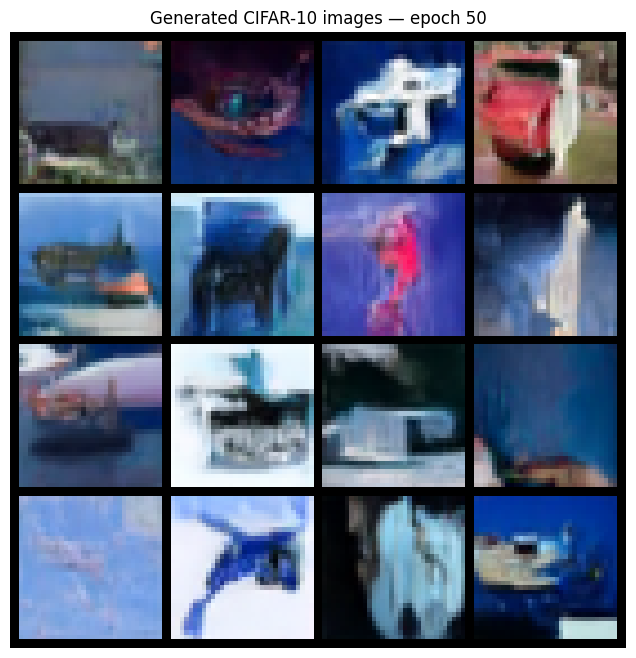

In [ ]:
grid = make_grid(
    generated_images,
    nrow=4,
    padding=2
)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0).cpu().numpy())
plt.title(f"Generated CIFAR-10 images — epoch {checkpoint['epoch']}")
plt.axis("off")
plt.show()

In [ ]:
train_until(100)
capture_samples(model, 100)

Epoch 51/100:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 51: mean MSE = 0.058679


Epoch 52/100:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 52: mean MSE = 0.058486


Epoch 53/100:   0%|          | 0/1407 [00:00<?, ?it/s]

...

Epoch 99/100:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 99: mean MSE = 0.057722


Epoch 100/100:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 100: mean MSE = 0.057792


Generating images:   0%|          | 0/1000 [00:00<?, ?it/s]

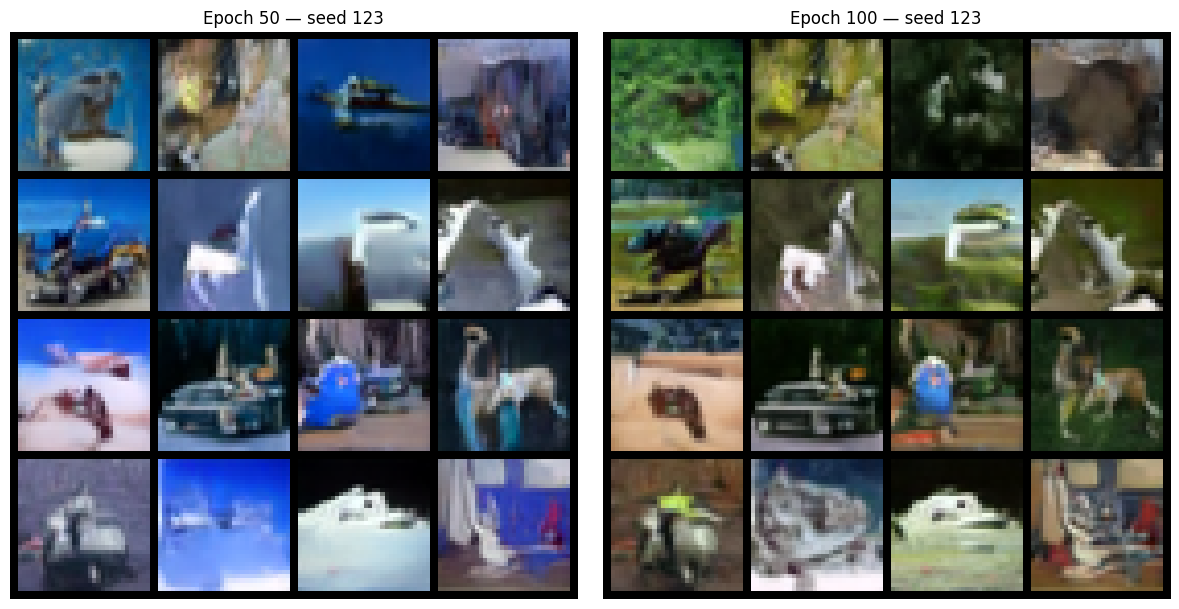

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, epoch_number in zip(axes, [50, 100]):
    path = (
        PROJECT_DIR
        / f"ddpm_{SCHEDULE}_epoch_{epoch_number}_seed123.png"
    )

    with Image.open(path) as image:
        ax.imshow(image)

    ax.set_title(f"Epoch {epoch_number} — seed 123")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
train_until(150)
capture_samples(model, 150)

Epoch 101/150:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 101: mean MSE = 0.057648


Epoch 102/150:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 102: mean MSE = 0.057641


Epoch 103/150:   0%|          | 0/1407 [00:00<?, ?it/s]

...

Epoch 149/150:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 149: mean MSE = 0.057077


Epoch 150/150:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 150: mean MSE = 0.057333


Generating images:   0%|          | 0/1000 [00:00<?, ?it/s]

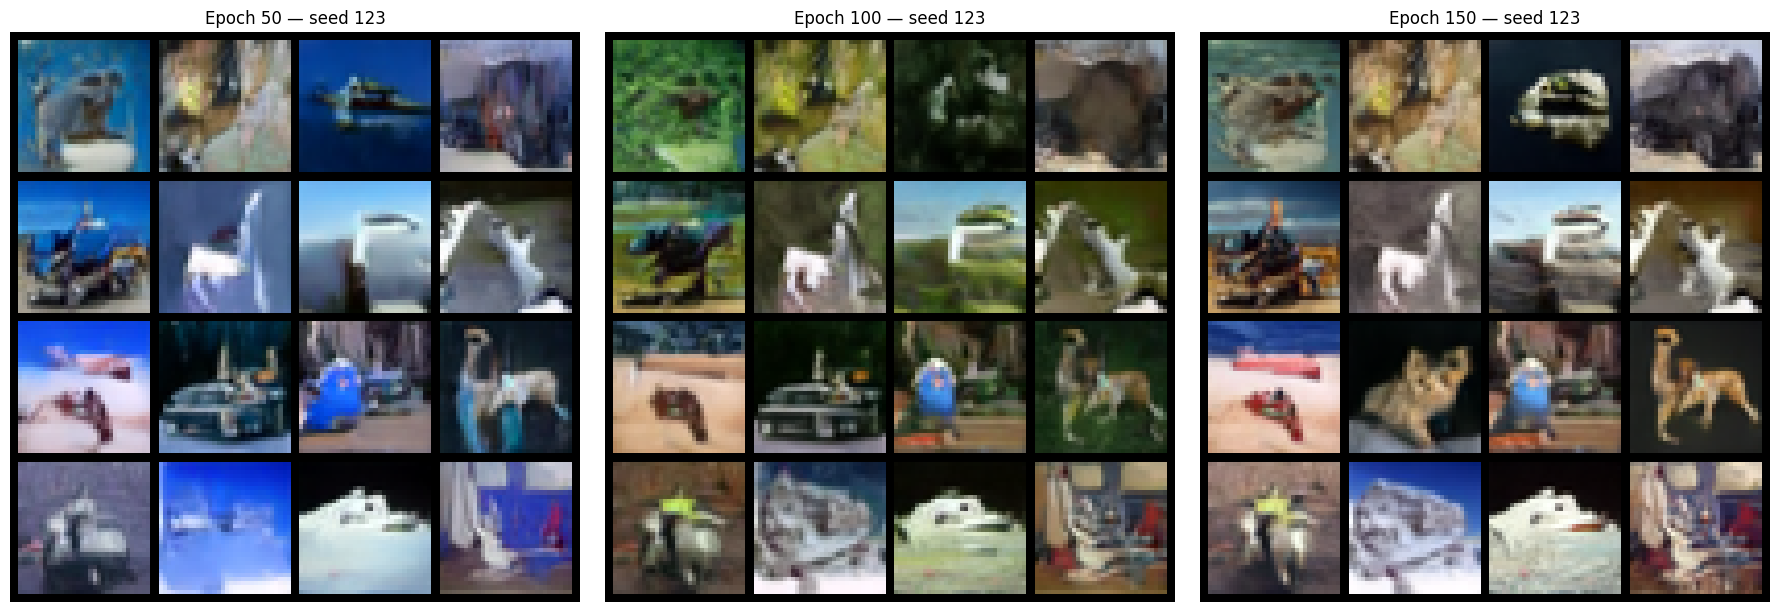

In [ ]:
epochs_to_compare = [50, 100, 150]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

for ax, epoch_number in zip(axes, epochs_to_compare):
    image_path = (
        PROJECT_DIR
        / f"ddpm_{SCHEDULE}_epoch_{epoch_number}_seed123.png"
    )

    with Image.open(image_path) as image:
        ax.imshow(image)

    ax.set_title(f"Epoch {epoch_number} — seed 123")
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / f"ddpm_{SCHEDULE}_epoch_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [ ]:
train_until(200)
capture_samples(model, 100)

Epoch 151/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 151: mean MSE = 0.056729


Epoch 152/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 152: mean MSE = 0.056240


Epoch 153/200:   0%|          | 0/1407 [00:00<?, ?it/s]

...

Epoch 199/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 199: mean MSE = 0.056357


Epoch 200/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 200: mean MSE = 0.056250


Generating images:   0%|          | 0/1000 [00:00<?, ?it/s]

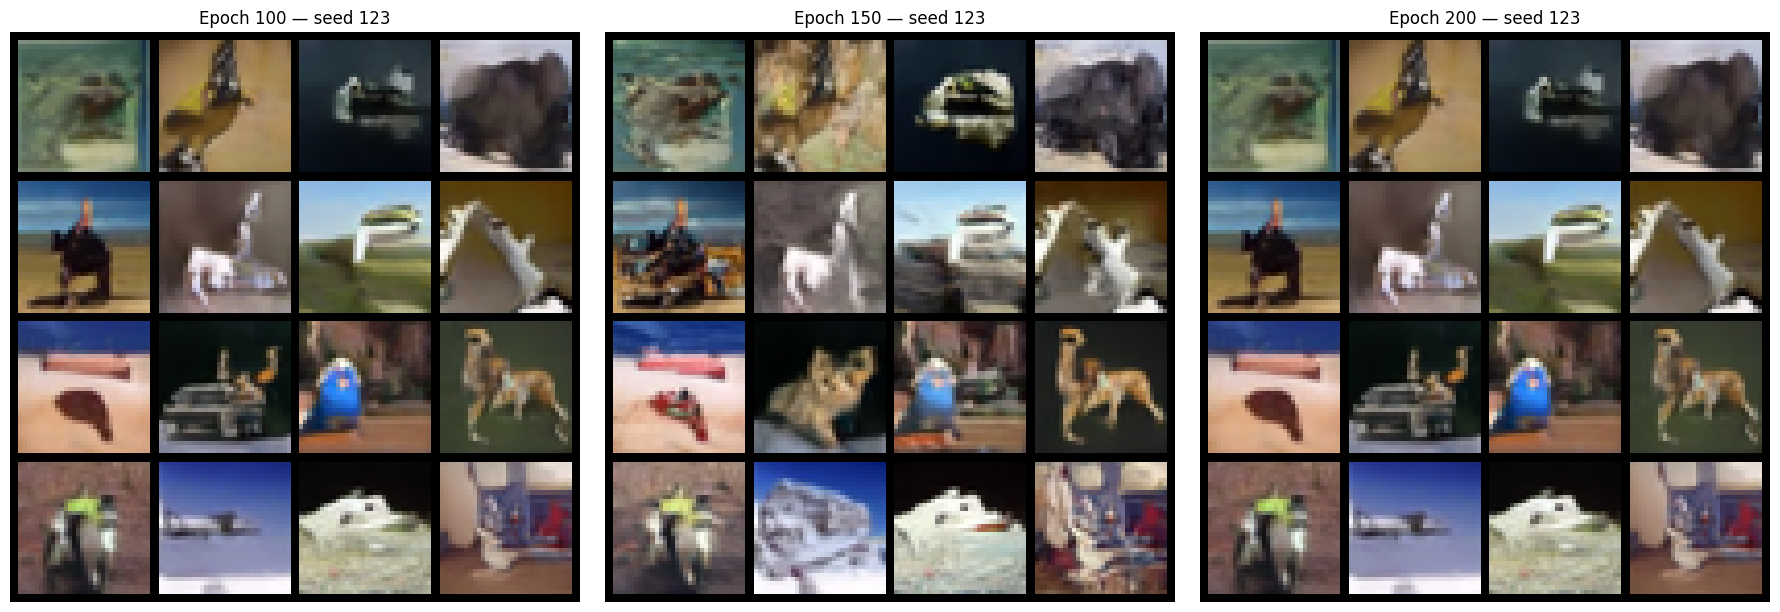

In [ ]:
epochs_to_compare = [100, 150, 200]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

for ax, epoch_number in zip(axes, epochs_to_compare):
    image_path = (
        PROJECT_DIR
        / f"ddpm_{SCHEDULE}_epoch_{epoch_number}_seed123.png"
    )

    with Image.open(image_path) as image:
        ax.imshow(image)

    ax.set_title(f"Epoch {epoch_number} — seed 123")
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / f"ddpm_{SCHEDULE}_epoch_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [ ]:
torch.manual_seed(123)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(123)

generated_images = sample_images(
    model,
    num_images=16,
    image_size=32
)

image_path = (
    PROJECT_DIR
    / f"ddpm_{SCHEDULE}_epoch_200_seed123.png"
)

# Output is already in [0, 1]: no additional normalization.
save_image(
    generated_images,
    image_path,
    nrow=4,
    normalize=False
)

print("Saved:", image_path)

grid = make_grid(generated_images, nrow=4)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.axis("off")
plt.show()

In [ ]:
checkpoint_path = PROJECT_DIR / f"ddpm_{SCHEDULE}_epoch_200.pt"#aves the model weights, optimizer state, configuration, noise schedule, loss history, and data-split indices.

torch.save(
    {
        "epoch": 200,
        "model_config": MODEL_CONFIG,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "schedule": SCHEDULE,
        "timesteps": TIMESTEPS,
        "betas": betas.detach().cpu(),
        "loss_history": loss_history,
        "train_indices": checkpoint["train_indices"],
        "val_indices": checkpoint["val_indices"]
    },
    checkpoint_path
)

# Verify the saved checkpoint
verified = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Saved:", checkpoint_path)
print("Verified epoch:", verified["epoch"])
print("Size (MB):", round(checkpoint_path.stat().st_size / 1e6, 2))

In [ ]:
print("Project folder exists:", PROJECT_DIR.is_dir())

if PROJECT_DIR.is_dir():
    print("\nSaved checkpoint and result files:")
    for path in sorted(PROJECT_DIR.rglob("*")):
        if path.is_file() and path.suffix in {".pt", ".json"}:
            print(path)

Project folder exists: True

Saved checkpoint and result files:
/content/drive/MyDrive/DDPM/cosine_epoch_200_evaluation_images.pt
/content/drive/MyDrive/DDPM/cosine_epoch_200_metrics.json
/content/drive/MyDrive/DDPM/data/cifar10_split.pt
/content/drive/MyDrive/DDPM/ddpm_cosine_epoch_100.pt
/content/drive/MyDrive/DDPM/ddpm_cosine_epoch_150.pt
/content/drive/MyDrive/DDPM/ddpm_cosine_epoch_200.pt
/content/drive/MyDrive/DDPM/ddpm_cosine_epoch_50.pt
/content/drive/MyDrive/DDPM/ddpm_cosine_epoch_60.pt
/content/drive/MyDrive/DDPM/ddpm_cosine_latest.pt


In [23]:
#Load epoch 200
checkpoint_200 = torch.load(
    PROJECT_DIR / "ddpm_cosine_epoch_200.pt",
    map_location="cpu",
    weights_only=True
)

print("Loaded epoch:", checkpoint_200["epoch"])

Loaded epoch: 200


In [14]:
@torch.no_grad()#function generates new images using trained DDPM
def generate_samples(
    model,
    saved_betas,
    num_images=16,
    seed=123,
    show_progress=True
):
    model_device = next(model.parameters()).device

    betas = saved_betas.to(model_device)
    alphas = 1.0 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)

    alpha_bars_prev = torch.cat([
        torch.ones(1, device=model_device),
        alpha_bars[:-1]
    ])

    variance = (
        betas * (1.0 - alpha_bars_prev)
        / (1.0 - alpha_bars)
    )

    coef1 = (
        betas * alpha_bars_prev.sqrt()
        / (1.0 - alpha_bars)
    )

    coef2 = (
        (1.0 - alpha_bars_prev) * alphas.sqrt()
        / (1.0 - alpha_bars)
    )

    generator = torch.Generator(
        device=model_device
    ).manual_seed(seed)

    x = torch.randn(
        num_images, 3, 32, 32,
        device=model_device,
        generator=generator
    )

    was_training = model.training
    model.eval()

    try:
        for step in tqdm(
            reversed(range(len(betas))),
            total=len(betas),
            desc="Generating images",
            disable=not show_progress
        ):
            t = torch.full(
                (num_images,),
                step,
                dtype=torch.long,
                device=model_device
            )

            predicted_noise = model(x, t)

            predicted_x0 = (
                x
                - (1.0 - alpha_bars[step]).sqrt()
                * predicted_noise
            ) / alpha_bars[step].sqrt()

            predicted_x0 = predicted_x0.clamp(-1, 1)

            mean = (
                coef1[step] * predicted_x0
                + coef2[step] * x
            )

            if step > 0:
                noise = torch.randn(
                    x.shape,
                    device=model_device,
                    generator=generator
                )

                x = mean + variance[step].sqrt() * noise
            else:
                x = mean

        return ((x + 1) / 2).clamp(0, 1).cpu()

    finally:
        model.train(was_training)

Generating images:   0%|          | 0/1000 [00:00<?, ?it/s]

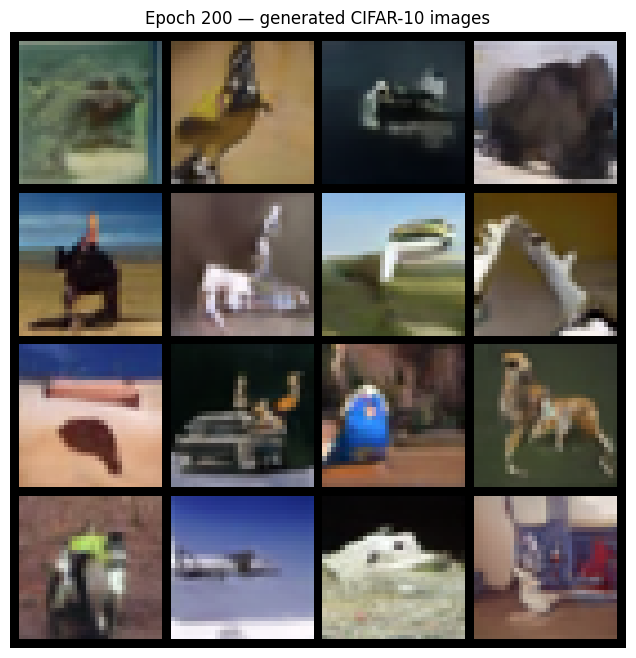

In [ ]:
#do not rerun
generated_images_200 = generate_samples(
    model_200,
    checkpoint_200["betas"],
    num_images=16,
    seed=123
)

grid = make_grid(
    generated_images_200,
    nrow=4,
    padding=2
)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.title("Epoch 200 — generated CIFAR-10 images")
plt.axis("off")
plt.show()

save_image(
    generated_images_200,
    PROJECT_DIR / "ddpm_cosine_epoch_200_evaluation_grid.png",
    nrow=4,
    padding=2
)

In [24]:
#preparing the real validation images for comparison with generated images when calculating FID.
real_source = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=True,
    download=True
)

val_indices = checkpoint_200["val_indices"]

real_uint8 = torch.from_numpy(
    real_source.data[val_indices].copy()
).permute(0, 3, 1, 2).contiguous()

print("Validation image shape:", real_uint8.shape)
print("Pixel dtype:", real_uint8.dtype)

Validation image shape: torch.Size([5000, 3, 32, 32])
Pixel dtype: torch.uint8


In [ ]:
#do not rerun
NUM_SAMPLES = min(5000, len(real_uint8))
GENERATION_BATCH_SIZE = 32

fake_batches = []

for start in tqdm(
    range(0, NUM_SAMPLES, GENERATION_BATCH_SIZE),
    desc="Generating evaluation batches"
):
    batch_size = min(
        GENERATION_BATCH_SIZE,
        NUM_SAMPLES - start
    )

    samples = generate_samples(
        model_200,
        checkpoint_200["betas"],
        num_images=batch_size,
        seed=10000 + start,
        show_progress=False
    )

    # Metric input: RGB uint8 images in [0, 255]
    fake_batches.append(
        (samples * 255).round().clamp(0, 255).to(torch.uint8)
    )

fake_uint8 = torch.cat(fake_batches, dim=0)

# Save generated evaluation images to avoid generating them again
torch.save(
    {
        "epoch": checkpoint_200["epoch"],
        "images": fake_uint8,
        "generation_batch_size": GENERATION_BATCH_SIZE
    },
    PROJECT_DIR / "cosine_epoch_200_evaluation_images.pt"
)

print("Generated image shape:", fake_uint8.shape)

Generating evaluation batches:   0%|          | 0/157 [00:00<?, ?it/s]

Generated image shape: torch.Size([5000, 3, 32, 32])


In [22]:
#load the saved images from the above cell
saved_images = torch.load(
    PROJECT_DIR / "cosine_epoch_200_evaluation_images.pt",
    map_location="cpu",
    weights_only=True
)

fake_uint8 = saved_images["images"]
NUM_SAMPLES = len(fake_uint8)
GENERATION_BATCH_SIZE = saved_images["generation_batch_size"]

print("Restored image shape:", fake_uint8.shape)

Restored image shape: torch.Size([5000, 3, 32, 32])


In [16]:
#this class wraps image tensor as a PyTorch dataset, so torch_fidelity can read the images in batches.
class ImageTensorDataset(Dataset):
    def __init__(self, images):
        self.images = images

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.images[index]


In [ ]:
#calculates FID and Inception Score, then saves the results to Google Drive. Do not reun

NUM_SAMPLES = len(fake_uint8)

assert len(real_uint8) >= NUM_SAMPLES
assert fake_uint8.dtype == torch.uint8
assert real_uint8.dtype == torch.uint8

metrics = torch_fidelity.calculate_metrics(
    input1=ImageTensorDataset(fake_uint8),
    input2=ImageTensorDataset(real_uint8[:NUM_SAMPLES]),
    cuda=torch.cuda.is_available(),
    batch_size=64,
    fid=True,
    isc=True,
    kid=False,
    verbose=True
)

print("\nEpoch-200 evaluation")
print("FID:", metrics["frechet_inception_distance"])
print("Inception Score:", metrics["inception_score_mean"])
print("IS standard deviation:", metrics["inception_score_std"])

report = {
    "epoch": checkpoint_200["epoch"],
    "schedule": checkpoint_200["schedule"],
    "num_real_images": NUM_SAMPLES,
    "num_generated_images": NUM_SAMPLES,
    **{key: float(value) for key, value in metrics.items()}
}

results_path = PROJECT_DIR / "cosine_epoch_200_metrics.json"

with open(results_path, "w") as file:
    json.dump(report, file, indent=2)

print("\nResults saved:", results_path)

In [ ]:
with open(PROJECT_DIR / "cosine_epoch_200_metrics.json") as file:
    results = json.load(file)

print("Epoch:", results["epoch"])
print("FID:", results["frechet_inception_distance"])
print("Inception Score:", results["inception_score_mean"])
print("IS standard deviation:", results["inception_score_std"])

Epoch: 200
FID: 39.95458775526947
Inception Score: 6.820897130832445
IS standard deviation: 0.27783091230830204


## *Fixed seeds for saved checkpoint*

In [ ]:
#do not rerun
for epoch_number in [50, 100, 150, 200]:
    saved_checkpoint = torch.load(
        PROJECT_DIR / f"ddpm_cosine_epoch_{epoch_number}.pt",
        map_location="cpu",
        weights_only=True
    )

    sample_model = DiffusionUNet(
        **saved_checkpoint["model_config"]
    ).to(device)

    sample_model.load_state_dict(
        saved_checkpoint["model_state_dict"]
    )

    samples = generate_samples(
        sample_model,
        saved_checkpoint["betas"],
        num_images=16,
        seed=123,
        show_progress=False
    )

    save_image(
        samples,
        PROJECT_DIR
        / f"ddpm_cosine_epoch_{epoch_number}_seed123.png",
        nrow=4,
        padding=2
    )

    del sample_model

print("Fixed-seed grids saved for the retained checkpoints.")

Fixed-seed grids saved for the retained checkpoints.


# Linear schedule

Linear schedule as a comparison experiment: its noise variance increases evenly from 0.0001 to 0.02. Comparing it with cosine helps to test whether the schedule affects generation quality.

In [25]:
# for both linear schedule with attention and no attention
# Reuse the already loaded epoch-200 checkpoint
reference = checkpoint_200

# Confirm the original training split is being reused
assert list(train_data.indices) == list(
    reference["train_indices"]
)

# Separate loader with a fresh shuffle seed for the linear experiment
linear_loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    persistent_workers=True,
    generator=torch.Generator().manual_seed(42)
)

print("Training images:", len(train_data))

Training images: 45000


## create a linear model

Separate variable names were used so it does not replace the cosine model or schedule

In [19]:
torch.manual_seed(42)

linear_config = reference["model_config"]
linear_timesteps = reference["timesteps"]
linear_target_epochs = 200

linear_model = DiffusionUNet(
    **linear_config
).to(device)

linear_optimizer = torch.optim.AdamW(
    linear_model.parameters(),
    lr=2e-4,
    weight_decay=0.0
)

linear_latest_path = PROJECT_DIR / "ddpm_linear_latest.pt"

if linear_latest_path.is_file():
    linear_saved = torch.load(
        linear_latest_path,
        map_location="cpu",
        weights_only=True
    )

    assert linear_saved["schedule"] == "linear"
    assert linear_saved["model_config"] == linear_config
    assert linear_saved["timesteps"] == linear_timesteps
    assert (
        linear_saved["train_indices"]
        == reference["train_indices"]
    )
    assert (
        linear_saved["val_indices"]
        == reference["val_indices"]
    )

    linear_model.load_state_dict(
        linear_saved["model_state_dict"]
    )

    linear_optimizer.load_state_dict(
        linear_saved["optimizer_state_dict"]
    )

    linear_betas = linear_saved["betas"].to(device)
    linear_history = list(linear_saved["loss_history"])
    linear_completed_epoch = linear_saved["epoch"]

    print("Resuming linear epoch:", linear_completed_epoch)

else:
    # Linear increase in noise variance
    linear_betas = torch.linspace(
        1e-4,
        0.02,
        linear_timesteps,
        dtype=torch.float32,
        device=device
    )

    linear_history = []
    linear_completed_epoch = 0

    print("Starting a fresh linear model.")

linear_alpha_bars = torch.cumprod(
    1.0 - linear_betas,
    dim=0
)

print("Next epoch:", linear_completed_epoch + 1)

Resuming linear epoch: 200
Next epoch: 201


## Define checkpoint saving

In [20]:
def save_linear_checkpoint(epoch_number):
    payload = {
        "epoch": epoch_number,
        "model_config": linear_config,
        "model_state_dict": linear_model.state_dict(),
        "optimizer_state_dict": linear_optimizer.state_dict(),
        "schedule": "linear",
        "timesteps": linear_timesteps,
        "betas": linear_betas.detach().cpu(),
        "loss_history": linear_history,
        "train_indices": reference["train_indices"],
        "val_indices": reference["val_indices"]
    }

    temporary_path = PROJECT_DIR / "ddpm_linear_latest.tmp"

    torch.save(payload, temporary_path)
    temporary_path.replace(linear_latest_path)

    if epoch_number in {50, 100, 150, 200}:
        torch.save(
            payload,
            PROJECT_DIR / f"ddpm_linear_epoch_{epoch_number}.pt"
        )

## Train the linear model

In [ ]:
#do not rerun
for epoch in range(
    linear_completed_epoch + 1,
    linear_target_epochs + 1
):
    linear_model.train()

    total_loss = 0.0
    total_images = 0

    progress = tqdm(
        linear_loader,
        desc=f"Linear epoch {epoch}/{linear_target_epochs}"
    )

    for images, _ in progress:
        images = images.to(device, non_blocking=True)

        t = torch.randint(
            0,
            linear_timesteps,
            (images.size(0),),
            device=device
        )

        target_noise = torch.randn_like(images)

        alpha_bar = linear_alpha_bars[t].view(
            -1, 1, 1, 1
        )

        noisy_images = (
            alpha_bar.sqrt() * images
            + (1.0 - alpha_bar).sqrt() * target_noise
        )

        linear_optimizer.zero_grad(set_to_none=True)

        predicted_noise = linear_model(noisy_images, t)

        loss = F.mse_loss(
            predicted_noise,
            target_noise
        )

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss detected.")

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            linear_model.parameters(),
            max_norm=1.0
        )

        linear_optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_images += batch_size

        progress.set_postfix(mse=f"{loss.item():.4f}")

    epoch_loss = total_loss / total_images
    linear_history.append(epoch_loss)

    save_linear_checkpoint(epoch)
    linear_completed_epoch = epoch

    print(
        f"Linear epoch {epoch}: mean MSE = {epoch_loss:.6f}"
    )

print("Completed linear epoch:", linear_completed_epoch)

Linear epoch 49/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Linear epoch 49: mean MSE = 0.031915


Linear epoch 50/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Linear epoch 50: mean MSE = 0.031069


Linear epoch 51/200:   0%|          | 0/1407 [00:00<?, ?it/s]

...

Linear epoch 198: mean MSE = 0.030228


Linear epoch 199/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Linear epoch 199: mean MSE = 0.030143


Linear epoch 200/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Linear epoch 200: mean MSE = 0.030607
Completed linear epoch: 200


## Generate linear samples

Generating images:   0%|          | 0/1000 [00:00<?, ?it/s]

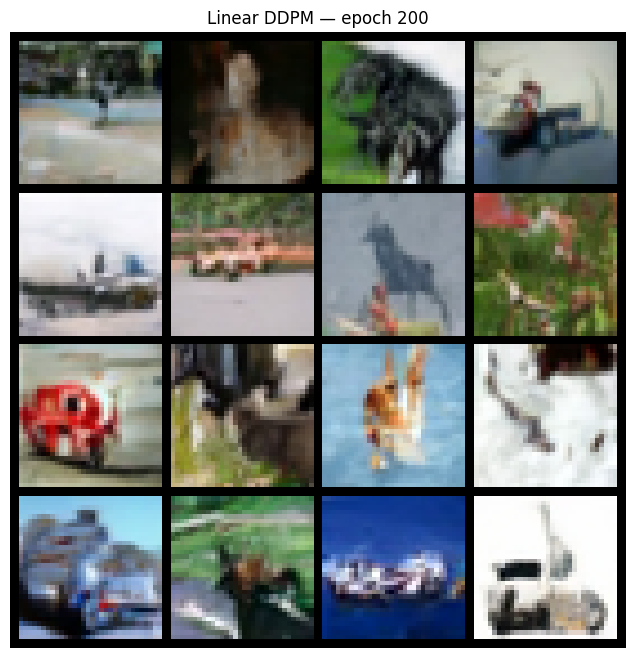

In [ ]:
#do not rerun
linear_samples = generate_samples(
    linear_model,
    linear_betas,
    num_images=16,
    seed=123
)

grid = make_grid(linear_samples, nrow=4, padding=2)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0).cpu().numpy())
plt.title(f"Linear DDPM — epoch {linear_completed_epoch}")
plt.axis("off")
plt.show()

save_image(
    linear_samples,
    PROJECT_DIR
    / f"ddpm_linear_epoch_{linear_completed_epoch}_seed123.png",
    nrow=4,
    padding=2
)

In [26]:
linear_checkpoint = torch.load(
    PROJECT_DIR / "ddpm_linear_epoch_200.pt",
    map_location="cpu",
    weights_only=True
)

assert linear_checkpoint["epoch"] == 200
assert linear_checkpoint["schedule"] == "linear"

linear_model = DiffusionUNet(
    **linear_checkpoint["model_config"]
).to(device)

linear_model.load_state_dict(
    linear_checkpoint["model_state_dict"]
)

linear_model.eval()

print("Loaded linear epoch:", linear_checkpoint["epoch"])

Loaded linear epoch: 200


## Prepare the same real validation images

In [27]:
cosine_checkpoint = torch.load(
    PROJECT_DIR / "ddpm_cosine_epoch_200.pt",
    map_location="cpu",
    weights_only=True
)

assert (
    linear_checkpoint["val_indices"]
    == cosine_checkpoint["val_indices"]
), "Validation splits must match."

print("Validation splits match.")

Validation splits match.


In [28]:
assert (
    linear_checkpoint["val_indices"]
    == cosine_checkpoint["val_indices"]
), "Validation splits must match."

real_source = datasets.CIFAR10(
    root=str(PROJECT_DIR / "data"),
    train=True,
    download=True
)

real_uint8 = torch.from_numpy(
    real_source.data[
        linear_checkpoint["val_indices"]
    ].copy()
).permute(0, 3, 1, 2).contiguous()

NUM_SAMPLES = 5000
GENERATION_BATCH_SIZE = 32

assert len(real_uint8) >= NUM_SAMPLES

## Generate and save evaluation images

In [ ]:
#do not rerun
images_path = (
    PROJECT_DIR / "linear_epoch_200_evaluation_images.pt"
)

if images_path.is_file():
    saved_images = torch.load(
        images_path,
        map_location="cpu",
        weights_only=True
    )

    assert saved_images["epoch"] == 200
    assert saved_images["generation_batch_size"] == 32

    linear_fake_uint8 = saved_images["images"]

    assert len(linear_fake_uint8) == NUM_SAMPLES

    print("Loaded saved linear evaluation images.")

else:
    batches = []

    for start in tqdm(
        range(0, NUM_SAMPLES, GENERATION_BATCH_SIZE),
        desc="Generating linear evaluation batches"
    ):
        batch_size = min(
            GENERATION_BATCH_SIZE,
            NUM_SAMPLES - start
        )

        samples = generate_samples(
            linear_model,
            linear_checkpoint["betas"],
            num_images=batch_size,
            seed=10000 + start,
            show_progress=False
        )

        batches.append(
            (samples * 255)
            .round()
            .clamp(0, 255)
            .to(torch.uint8)
        )

    linear_fake_uint8 = torch.cat(batches, dim=0)

    torch.save(
        {
            "epoch": 200,
            "schedule": "linear",
            "generation_batch_size": GENERATION_BATCH_SIZE,
            "images": linear_fake_uint8
        },
        images_path
    )

    print("Saved:", images_path)

print("Generated images:", linear_fake_uint8.shape)

Generating linear evaluation batches:   0%|          | 0/157 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/DDPM/linear_epoch_200_evaluation_images.pt
Generated images: torch.Size([5000, 3, 32, 32])


## Calculate and save FID/Inception Score

In [ ]:
#do not rerun
results_path = PROJECT_DIR / "linear_epoch_200_metrics.json"

if results_path.is_file():
    with open(results_path) as file:
        linear_results = json.load(file)

    print("Loaded saved linear metrics.")

else:
    linear_metrics = torch_fidelity.calculate_metrics(
        input1=ImageTensorDataset(linear_fake_uint8),
        input2=ImageTensorDataset(real_uint8[:NUM_SAMPLES]),
        cuda=torch.cuda.is_available(),
        batch_size=64,
        fid=True,
        isc=True,
        kid=False,
        verbose=True
    )

    linear_results = {
        "epoch": 200,
        "schedule": "linear",
        "num_real_images": NUM_SAMPLES,
        "num_generated_images": NUM_SAMPLES,
        "generation_batch_size": GENERATION_BATCH_SIZE,
        **{
            key: float(value)
            for key, value in linear_metrics.items()
        }
    }

    with open(results_path, "w") as file:
        json.dump(linear_results, file, indent=2)

print("Linear FID:", linear_results["frechet_inception_distance"])
print("Linear IS:", linear_results["inception_score_mean"])
print("IS std:", linear_results["inception_score_std"])

Creating feature extractor "inception-v3-compat" with features ['logits_unbiased', '2048']
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:02<00:00, 37.4MB/s]
Extracting features from input1
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Processing samples:   0%|          | 0/5000 [00:00<?, ?samples/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: U

Linear FID: 39.07448962827533
Linear IS: 6.5577433496442
IS std: 0.2796397993362272


Frechet Inception Distance: 39.07449


## *fixed-seed grids for saved checkpoints*

In [ ]:
#do not rerun
for epoch_number in [50, 100, 150, 200]:
    saved_checkpoint = torch.load(
        PROJECT_DIR / f"ddpm_linear_epoch_{epoch_number}.pt",
        map_location="cpu",
        weights_only=True
    )

    sample_model = DiffusionUNet(
        **saved_checkpoint["model_config"]
    ).to(device)

    sample_model.load_state_dict(
        saved_checkpoint["model_state_dict"]
    )

    samples = generate_samples(
        sample_model,
        saved_checkpoint["betas"],
        num_images=16,
        seed=123,
        show_progress=False
    )

    save_image(
        samples,
        PROJECT_DIR
        / f"ddpm_linear_epoch_{epoch_number}_seed123.png",
        nrow=4,
        padding=2
    )

    del sample_model

print("Fixed-seed grids saved for the retained checkpoints.")

Fixed-seed grids saved for the retained checkpoints.


## *Loss histories*

Cosine: 200 recorded losses, epochs 1–200
Linear: 200 recorded losses, epochs 1–200


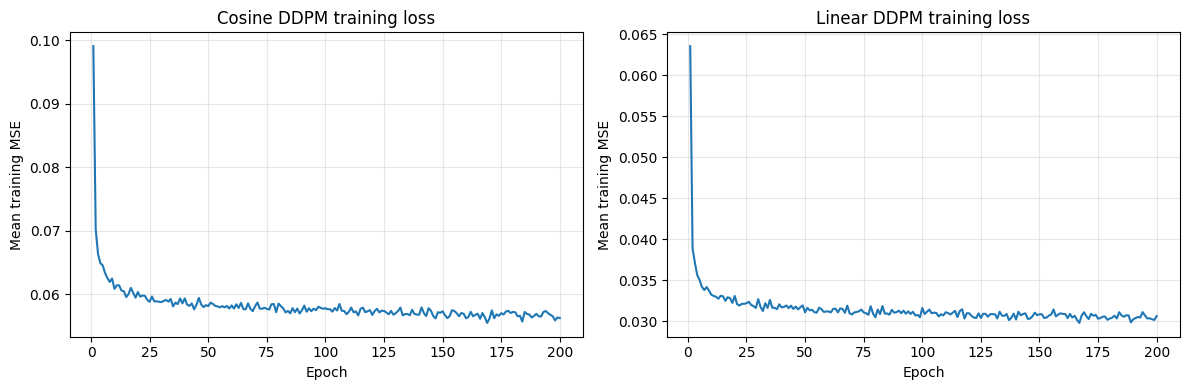

In [ ]:
from pathlib import Path
import torch
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/drive/MyDrive/DDPM")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, schedule in zip(axes, ["cosine", "linear"]):
    checkpoint = torch.load(
        PROJECT_DIR / f"ddpm_{schedule}_epoch_200.pt",
        map_location="cpu",
        weights_only=True
    )

    history = checkpoint["loss_history"]
    final_epoch = checkpoint["epoch"]

    # Handles histories containing only the most recent epochs
    first_epoch = final_epoch - len(history) + 1
    epochs = range(first_epoch, final_epoch + 1)

    ax.plot(epochs, history)
    ax.set_title(f"{schedule.capitalize()} DDPM training loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean training MSE")
    ax.grid(alpha=0.3)

    print(
        f"{schedule.capitalize()}: "
        f"{len(history)} recorded losses, "
        f"epochs {first_epoch}–{final_epoch}"
    )

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "ddpm_training_loss_curves.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Observations: Training Loss

- Both cosine and linear DDPM models show a sharp initial
  decrease in training loss, followed by gradual stabilization.
- Most improvement occurs in the first 20–30 epochs.
- Cosine DDPM loss decreases from approximately 0.099 to 0.056–0.057.
- Linear DDPM loss decreases from approximately 0.064 to 0.030–0.031.
- Both curves show small fluctuations without sustained loss explosions.
- Linear DDPM has lower training MSE, but this does not establish
  better generated-image quality because the noise schedules
  create different prediction tasks.
- FID, Inception Score, and generated-image inspection are needed
  to compare generation quality.
- Training loss alone cannot confirm or rule out overfitting.

## *Detecting failure modes*

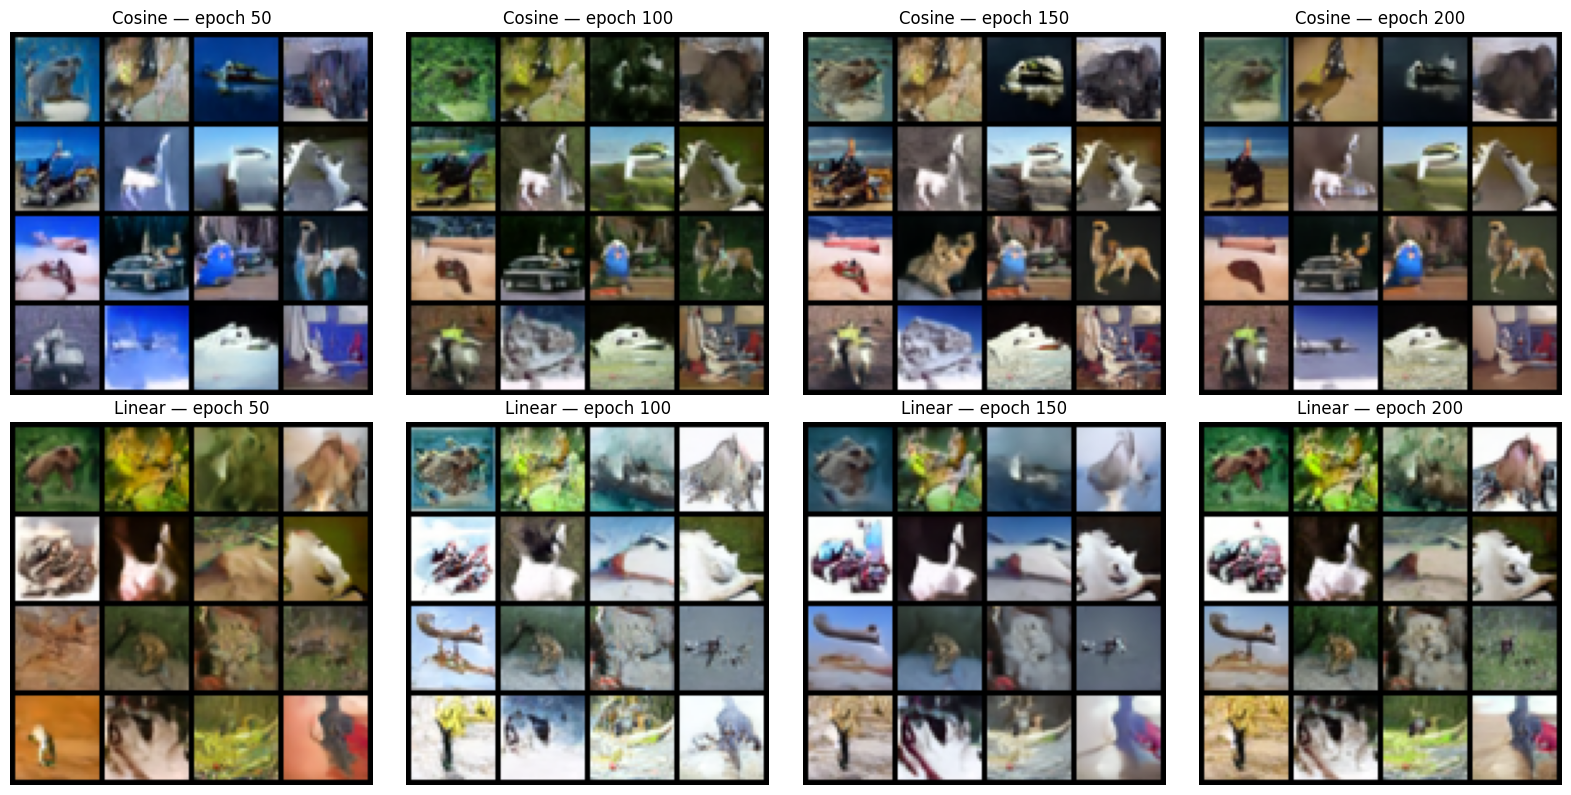

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

epochs = [50, 100, 150, 200]
schedules = ["cosine", "linear"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for row, schedule in enumerate(schedules):
    for col, epoch in enumerate(epochs):
        path = (
            PROJECT_DIR
            / f"ddpm_{schedule}_epoch_{epoch}_seed123.png"
        )

        ax = axes[row, col]

        if path.is_file():
            with Image.open(path) as image:
                ax.imshow(image)
        else:
            ax.text(
                0.5, 0.5, "Grid not saved",
                ha="center", va="center"
            )

        ax.set_title(f"{schedule.capitalize()} — epoch {epoch}")
        ax.axis("off")

plt.tight_layout()
plt.savefig(
    PROJECT_DIR / "ddpm_qualitative_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

### Failure-Mode Observations

| Failure-mode check | Observation |
|---|---|
| **Mode collapse / repetition** | No obvious severe collapse within these grids: images vary in colour, background, and object-like shapes. This small sample cannot rule out reduced diversity. |
| **Blur and missing detail** | Both models produce soft textures and unclear boundaries. Some animals and vehicles remain difficult to identify. |
| **Structural distortion** | Several samples contain malformed bodies, ambiguous limbs, or incomplete vehicle-like structures. |
| **Checkerboard artifacts** | No strong, consistent checkerboard pattern is apparent at this display scale. Pixelation is expected from enlarging 32 × 32 images. |
| **Background–object separation** | Some objects blend into their backgrounds, reducing recognizability. |
| **Progress across epochs** | Some shapes become more coherent, but improvement is uneven. Epoch 200 is not visibly better than earlier checkpoints for every sample. |

**Note:** Similar images at corresponding positions across epochs are expected when using a fixed seed; this alone does not indicate mode collapse.

## Compare linear and cosine

In [29]:
with open(PROJECT_DIR / "cosine_epoch_200_metrics.json") as file:
    cosine_results = json.load(file)

with open(PROJECT_DIR / "linear_epoch_200_metrics.json") as file:
    linear_results = json.load(file)

assert (
    cosine_results["num_generated_images"]
    == linear_results["num_generated_images"]
), "Generated-image counts differ."

assert (
    cosine_results["num_real_images"]
    == linear_results["num_real_images"]
), "Real-image counts differ."

comparison = pd.DataFrame([
    {
        "Schedule": result["schedule"],
        "Epoch": result["epoch"],
        "FID": result["frechet_inception_distance"],
        "Inception Score": result["inception_score_mean"],
        "IS std": result["inception_score_std"]
    }
    for result in [cosine_results, linear_results]
])

display(comparison)

comparison.to_csv(
    PROJECT_DIR / "linear_vs_cosine_comparison.csv",
    index=False
)

,Schedule,Epoch,FID,Inception Score,IS std
0,cosine,200,39.954588,6.820897,0.277831
1,linear,200,39.074490,6.557743,0.279640


### Cosine vs. Linear Schedule Comparison

| Metric | Cosine | Linear | Observation |
|---|---:|---:|---|
| **FID ↓** | 39.95 | 39.07 | Linear is slightly better, with FID lower by **0.88**. |
| **Inception Score ↑** | 6.82 | 6.56 | Cosine is slightly better, with IS higher by **0.26**. |

**Note:** Lower FID and higher Inception Score are preferred. These single-run results show small differences; neither schedule is better on both metrics.

Both schedules show comparable results after 200 epochs. Linear slightly favours similarity to the real-image distribution according to FID, while cosine achieves a higher Inception Score. Neither schedule clearly dominates both metrics.
These are single-run estimates, so the small differences do not establish a consistent advantage. The reported IS standard deviation is across evaluation splits, not uncertainty across training runs

## Linear schedule with no attention

In [30]:
# removes all three attention layers while preserving timestep conditioning, residual blocks, and skip connections.
class NoAttentionUNet(DiffusionUNet):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

        self.encoder_attention = nn.Identity()
        self.middle_attention = nn.Identity()
        self.decoder_attention = nn.Identity()

In [31]:
# Replace linear-model initialization/resume cell
torch.manual_seed(42)

linear_config = reference["model_config"]
linear_timesteps = reference["timesteps"]
linear_target_epochs = 200

# Separate directory prevents overwriting existing experiments
NO_ATTN_DIR = PROJECT_DIR / "linear_no_attention"
NO_ATTN_DIR.mkdir(parents=True, exist_ok=True)

linear_latest_path = (
    NO_ATTN_DIR / "ddpm_linear_no_attention_latest.pt"
)

linear_model = NoAttentionUNet(
    **linear_config
).to(device)

linear_optimizer = torch.optim.AdamW(
    linear_model.parameters(),
    lr=2e-4,
    weight_decay=0.0
)

if linear_latest_path.is_file():
    linear_saved = torch.load(
        linear_latest_path,
        map_location="cpu",
        weights_only=True
    )

    assert linear_saved["architecture"] == "NoAttentionUNet"
    assert linear_saved["schedule"] == "linear"
    assert linear_saved["model_config"] == linear_config
    assert linear_saved["timesteps"] == linear_timesteps
    assert (
        linear_saved["train_indices"]
        == reference["train_indices"]
    )
    assert (
        linear_saved["val_indices"]
        == reference["val_indices"]
    )

    linear_model.load_state_dict(
        linear_saved["model_state_dict"]
    )

    linear_optimizer.load_state_dict(
        linear_saved["optimizer_state_dict"]
    )

    linear_betas = linear_saved["betas"].to(device)
    linear_history = list(linear_saved["loss_history"])
    linear_completed_epoch = linear_saved["epoch"]

    print("Resuming from epoch:", linear_completed_epoch)

else:
    linear_betas = torch.linspace(
        1e-4,
        0.02,
        linear_timesteps,
        device=device
    )

    linear_history = []
    linear_completed_epoch = 0

    print("Fresh no-attention model initialized.")

linear_alpha_bars = torch.cumprod(
    1.0 - linear_betas,
    dim=0
)

print("Next epoch:", linear_completed_epoch + 1)

Resuming from epoch: 200
Next epoch: 201


## Model, optimizer, schedule, and training history

In [ ]:
# Do not rerun during active training, because it recreates the model before restoring saved progress.
torch.manual_seed(42)

linear_config = reference["model_config"]
linear_timesteps = reference["timesteps"]
linear_target_epochs = 200

linear_latest_path = (
    NO_ATTN_DIR / "ddpm_linear_no_attention_latest.pt"
)

linear_model = NoAttentionUNet(
    **linear_config
).to(device)

linear_optimizer = torch.optim.AdamW(
    linear_model.parameters(),
    lr=2e-4,
    weight_decay=0.0
)

if linear_latest_path.is_file():
    saved = torch.load(
        linear_latest_path,
        map_location="cpu",
        weights_only=True
    )

    assert saved["architecture"] == "NoAttentionUNet"
    assert saved["schedule"] == "linear"
    assert saved["model_config"] == linear_config
    assert saved["timesteps"] == linear_timesteps
    assert saved["train_indices"] == reference["train_indices"]
    assert saved["val_indices"] == reference["val_indices"]

    linear_model.load_state_dict(saved["model_state_dict"])
    linear_optimizer.load_state_dict(saved["optimizer_state_dict"])

    linear_betas = saved["betas"].to(device)
    linear_history = list(saved["loss_history"])
    linear_completed_epoch = saved["epoch"]

    print("Restored epoch:", linear_completed_epoch)

else:
    linear_betas = torch.linspace(
        1e-4,
        0.02,
        linear_timesteps,
        device=device
    )

    linear_history = []
    linear_completed_epoch = 0

    print("Initialized a fresh no-attention model.")

linear_alpha_bars = torch.cumprod(
    1.0 - linear_betas,
    dim=0
)

print("Next epoch:", linear_completed_epoch + 1)

Initialized a fresh no-attention model.
Next epoch: 1


In [32]:
# checkpoint-saving function
def save_linear_checkpoint(epoch_number):
    payload = {
        "epoch": epoch_number,
        "architecture": "NoAttentionUNet",
        "model_config": linear_config,
        "model_state_dict": linear_model.state_dict(),
        "optimizer_state_dict": linear_optimizer.state_dict(),
        "schedule": "linear",
        "timesteps": linear_timesteps,
        "betas": linear_betas.detach().cpu(),
        "loss_history": linear_history,
        "train_indices": reference["train_indices"],
        "val_indices": reference["val_indices"]
    }

    temporary_path = (
        NO_ATTN_DIR / "ddpm_linear_no_attention_latest.tmp"
    )

    torch.save(payload, temporary_path)
    temporary_path.replace(linear_latest_path)

    if epoch_number in {50, 100, 150, 200}:
        torch.save(
            payload,
            NO_ATTN_DIR
            / f"ddpm_linear_no_attention_epoch_{epoch_number}.pt"
        )

## Training loop

In [ ]:
for epoch in range(
    linear_completed_epoch + 1,
    linear_target_epochs + 1
):
    linear_model.train()

    total_loss = 0.0
    total_images = 0

    progress = tqdm(
        linear_loader,
        desc=f"No-attention epoch {epoch}/{linear_target_epochs}"
    )

    for images, _ in progress:
        images = images.to(device, non_blocking=True)

        timesteps = torch.randint(
            0,
            linear_timesteps,
            (images.size(0),),
            device=device
        )

        target_noise = torch.randn_like(images)

        alpha_bar = linear_alpha_bars[timesteps].view(
            -1, 1, 1, 1
        )

        noisy_images = (
            alpha_bar.sqrt() * images
            + (1.0 - alpha_bar).sqrt() * target_noise
        )

        linear_optimizer.zero_grad(set_to_none=True)

        predicted_noise = linear_model(
            noisy_images,
            timesteps
        )

        loss = F.mse_loss(
            predicted_noise,
            target_noise
        )

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss detected.")

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            linear_model.parameters(),
            max_norm=1.0
        )

        linear_optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_images += batch_size

        progress.set_postfix(mse=f"{loss.item():.4f}")

    epoch_loss = total_loss / total_images
    linear_history.append(epoch_loss)

    save_linear_checkpoint(epoch)
    linear_completed_epoch = epoch

    print(f"Epoch {epoch}: mean MSE = {epoch_loss:.6f}")

print("Completed epoch:", linear_completed_epoch)

No-attention epoch 79/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 79: mean MSE = 0.032175


No-attention epoch 80/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 80: mean MSE = 0.031329


No-attention epoch 81/200:   0%|          | 0/1407 [00:00<?, ?it/s]

...

Epoch 198: mean MSE = 0.031239


No-attention epoch 199/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 199: mean MSE = 0.031632


No-attention epoch 200/200:   0%|          | 0/1407 [00:00<?, ?it/s]

Epoch 200: mean MSE = 0.031141
Completed epoch: 200


## generate and save samples

In [ ]:
samples = generate_samples(
    linear_model,
    linear_betas,
    num_images=16,
    seed=123
)

save_image(
    samples,
    NO_ATTN_DIR
    / f"linear_no_attention_epoch_{linear_completed_epoch}_seed123.png",
    nrow=4,
    padding=2
)

Generating images:   0%|          | 0/1000 [00:00<?, ?it/s]

## Load the completed checkpoint and real validation images

In [33]:
import json
import torch
from torchvision import datasets

checkpoint_no_attn = torch.load(
    NO_ATTN_DIR / "ddpm_linear_no_attention_epoch_200.pt",
    map_location="cpu",
    weights_only=True
)

assert checkpoint_no_attn["epoch"] == 200

eval_model = NoAttentionUNet(
    **checkpoint_no_attn["model_config"]
).to(device)

eval_model.load_state_dict(
    checkpoint_no_attn["model_state_dict"]
)

eval_model.eval()

real_source = datasets.CIFAR10(
    root=str(PROJECT_DIR / "data"),
    train=True,
    download=True
)

real_uint8 = torch.from_numpy(
    real_source.data[
        checkpoint_no_attn["val_indices"]
    ].copy()
).permute(0, 3, 1, 2).contiguous()

NUM_SAMPLES = 5000
assert len(real_uint8) >= NUM_SAMPLES

## Generate evaluation images

In [35]:
images_path = NO_ATTN_DIR / "evaluation_images_epoch_200.pt"

if images_path.is_file():
    fake_uint8 = torch.load(
        images_path,
        map_location="cpu",
        weights_only=True
    )

else:
    batches = []

    for start in tqdm(
        range(0, NUM_SAMPLES, 32),
        desc="Generating evaluation batches"
    ):
        samples = generate_samples(
            eval_model,
            checkpoint_no_attn["betas"],
            num_images=min(32, NUM_SAMPLES - start),
            seed=10000 + start,
            show_progress=False
        )

        batches.append(
            (samples * 255)
            .round()
            .clamp(0, 255)
            .to(torch.uint8)
            .cpu()
        )

    fake_uint8 = torch.cat(batches)
    torch.save(fake_uint8, images_path)

assert len(fake_uint8) == NUM_SAMPLES
print("Evaluation images:", fake_uint8.shape)

Evaluation images: torch.Size([5000, 3, 32, 32])


## Calculate and save metrics

In [ ]:
class ImageTensorDataset(Dataset):
    def __init__(self, images):
        self.images = images

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.images[index]


results_path = NO_ATTN_DIR / "metrics_epoch_200.json"

if results_path.is_file():
    with open(results_path) as file:
        no_attn_results = json.load(file)

else:
    metrics = torch_fidelity.calculate_metrics(
        input1=ImageTensorDataset(fake_uint8),
        input2=ImageTensorDataset(real_uint8[:NUM_SAMPLES]),
        cuda=(device.type == "cuda"),
        batch_size=64,
        fid=True,
        isc=True,
        kid=False,
        verbose=True
    )

    no_attn_results = {
        "model": "Linear DDPM without attention",
        "epoch": 200,
        "num_real_images": NUM_SAMPLES,
        "num_generated_images": NUM_SAMPLES,
        "generation_batch_size": 32,
        **{key: float(value) for key, value in metrics.items()}
    }

    with open(results_path, "w") as file:
        json.dump(no_attn_results, file, indent=2)

print("FID:", no_attn_results["frechet_inception_distance"])
print("Inception Score:", no_attn_results["inception_score_mean"])
print("IS std:", no_attn_results["inception_score_std"])

## Compare all three experiments

In [ ]:
with open(PROJECT_DIR / "cosine_epoch_200_metrics.json") as file:
    cosine_results = json.load(file)

with open(PROJECT_DIR / "linear_epoch_200_metrics.json") as file:
    linear_results = json.load(file)

rows = []

for name, result in [
    ("Cosine + attention", cosine_results),
    ("Linear + attention", linear_results),
    ("Linear without attention", no_attn_results)
]:
    assert result["num_generated_images"] == NUM_SAMPLES
    assert result["num_real_images"] == NUM_SAMPLES

    rows.append({
        "Model": name,
        "Epoch": result["epoch"],
        "FID": result["frechet_inception_distance"],
        "Inception Score": result["inception_score_mean"],
        "IS std": result["inception_score_std"]
    })

comparison = pd.DataFrame(rows)
display(comparison)

comparison.to_csv(
    PROJECT_DIR / "ddpm_ablation_comparison.csv",
    index=False
)

,Model,Epoch,FID,Inception Score,IS std
0,Cosine + attention,200,39.954588,6.820897,0.277831
1,Linear + attention,200,39.074490,6.557743,0.279640
2,Linear without attention,200,52.321832,5.604111,0.176701


In [38]:
from pathlib import Path
import json
import math
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/DDPM")
results_path = (
    PROJECT_DIR / "linear_no_attention/metrics_epoch_200.json"
)
csv_path = PROJECT_DIR / "ddpm_ablation_comparison.csv"

comparison = pd.read_csv(csv_path)

matched = comparison[
    comparison["Model"]
    .str.strip()
    .str.casefold()
    .eq("linear without attention")
]

if len(matched) != 1:
    raise ValueError(
        "Expected exactly one 'Linear without attention' row. "
        "Inspect the CSV before continuing."
    )

row = matched.iloc[0]

if int(row["Epoch"]) != 200:
    raise ValueError("The saved row is not from epoch 200.")

scores = {
    "frechet_inception_distance": float(row["FID"]),
    "inception_score_mean": float(row["Inception Score"]),
    "inception_score_std": float(row["IS std"])
}

if not all(math.isfinite(value) for value in scores.values()):
    raise ValueError("The CSV contains missing or invalid scores.")

no_attn_results = {
    "model": "Linear DDPM without attention",
    "epoch": 200,
    # Your earlier evaluation used these sample counts
    "num_real_images": 5000,
    "num_generated_images": 5000,
    "generation_batch_size": 32,
    **scores
}

results_path.parent.mkdir(parents=True, exist_ok=True)

# Serialize before opening a file, then replace using a temporary file
text = json.dumps(no_attn_results, indent=2, allow_nan=False)
temporary_path = results_path.with_suffix(".tmp")
temporary_path.write_text(text, encoding="utf-8")
temporary_path.replace(results_path)

with open(results_path) as file:
    restored = json.load(file)

print("Recovered and verified:")
print(restored)

Recovered and verified:
{'model': 'Linear DDPM without attention', 'epoch': 200, 'num_real_images': 5000, 'num_generated_images': 5000, 'generation_batch_size': 32, 'frechet_inception_distance': 52.32183232253237, 'inception_score_mean': 5.6041105919883165, 'inception_score_std': 0.1767009382510746}
